# 04 · MONDAY EFFECT · RECONCILIATION WITH METATRADER 5 (AXI · BTC-JPY CFD)
**Alphaca Capital** · `MONDAY.btcusd.cfd.v1` · vehicle: Axi BTC-JPY CFD, H1 candles.

This notebook does everything that is **not** MetaTrader:

1. Loads the **Axi** H1 candles (already converted to UTC with `convert_axi_h1.py`) and checks their quality.
2. Runs the engine with the YAML rules and builds the trade list and a table of **every Monday** (traded or not).
3. Computes lot sizes and risk (hard limit) on Axi data.
4. Exports `engine_trades.csv` for the comparison.
5. **Once you have the Strategy Tester results**, compares trade by trade (dates, ATR%, percentile, prices, lots), measures the real spread and writes `reconciliacion_mt5_axi.json`.

Sections 5 to 9 skip themselves automatically while the tester files do not exist yet.

## 0 · CONFIGURATION

In [1]:
import json, re, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- engine: this notebook lives next to monday_effect_engine.py (or it is searched nearby)
for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "02_strategy_development" / "MondayEffect"):
    if (p / "monday_effect_engine.py").exists():
        sys.path.insert(0, str(p))
        break
import monday_effect_engine as me

# --- rules from the YAML MONDAY.btcusd.cfd.v1 (DO NOT touch: already through research)
PARAMS = dict(atr_pctl=40.0)
ENGINE = dict(atr_len=24, atr_method="sma", gap_mode="rows",
              pctl_window=8760, pctl_min_bars=4380, size_fraction=0.20)

# --- Axi data (output of convert_axi_h1.py)
CSV_UTC      = "../../data/axi/btcjpy_h1_utc.csv"   # copy the CSV here; if missing, ~/Downloads is searched
HOURLY_START = "2022-06-17 21:00"                   # first real hourly candle (the 3 daily ones are excluded)
TESTER_START = "2023-01-02"                         # first Monday of the tester (full warm-up)
TESTER_END   = "2026-10-23"

# --- tester account
DEPOSIT         = 50_000.0     # tester deposit (account currency)
ACCOUNT_PER_JPY = 1 / 155.0    # account currency per 1 JPY (approx., only for engine lots; None = skip)
HARD_LIMIT      = 0.09

# --- tester results (fill in after running MT5; if missing, that part is skipped)
TESTER_A = dict(report="tester/report_A.xlsx", log="tester/log_A.txt")   # Pass A: Open prices only
TESTER_B = dict(report="tester/report_B.xlsx", log="tester/log_B.txt")   # Pass B: 1 minute OHLC / real ticks

OUT_DIR = Path("results")
OUT_DIR.mkdir(exist_ok=True)

## 1 · AXI DATA AND QUALITY

In [2]:
csv_path = Path(CSV_UTC)
if not csv_path.exists():
    csv_path = Path.home() / "Downloads" / "btcjpy_h1_utc.csv"
print("CSV:", csv_path)

# Axi BTC-JPY preset (min lot 0.01, step 0.01, contract 1, long swap -15 % annual, rollover 22:00 UTC).
# Cost is 0 ON PURPOSE: the price difference against the tester then MEASURES Axi's real spread/slippage.
me.apply_cfd_preset("axi_btcjpy", cost_bps_per_side=0.0,
                    quote_to_account=ACCOUNT_PER_JPY if ACCOUNT_PER_JPY else 1.0)
me.set_engine_defaults(data_source="csv_hourly", csv_path=str(csv_path), **ENGINE)

df_raw = me.load_data(start=HOURLY_START)

d = df_raw.index.to_series().diff().dropna()
gaps = d[d != pd.Timedelta(hours=1)]
print(f"bars: {len(df_raw):,} | {df_raw.index[0]} -> {df_raw.index[-1]} (UTC)")
print(f"steps different from 1 h: {len(gaps)}")
gap_tbl = pd.DataFrame({"until": gaps.index, "gap_h": (gaps / pd.Timedelta(hours=1)).values})
gap_tbl.sort_values("gap_h", ascending=False).head(10)

CSV: /Users/luyandy/Downloads/btcjpy_h1_utc.csv
bars: 38,052 | 2022-06-17 21:00:00 -> 2026-10-24 18:00:00 (UTC)
steps different from 1 h: 43


,until,gap_h
7,2022-12-25 22:00:00,24.0
11,2023-09-24 14:00:00,17.0
10,2023-09-23 21:00:00,10.0
13,2023-10-28 21:00:00,10.0
21,2024-07-06 06:00:00,5.0
20,2024-06-29 05:00:00,5.0
37,2026-04-04 02:00:00,3.0
24,2025-10-24 23:00:00,3.0
0,2022-06-18 13:00:00,3.0
42,2026-09-20 16:00:00,3.0


## 2 · ENGINE: TRADES AND TABLE OF EVERY MONDAY

In [3]:
df = me.prepare(df_raw)
trades_all = me.run_monday_backtest(df, **PARAMS)      # cost 0 + Axi swap (the preset defaults)
trades = trades_all[(trades_all.entry_time >= TESTER_START) &
                    (trades_all.entry_time <= TESTER_END)].reset_index(drop=True)

# every Monday with a contiguous signal candle, with the decision and the edge flags
ent = df[df.entry_ok]
mon = pd.DataFrame({
    "entry_utc": ent.index,
    "atr_pct": ent.atr_sig.values,
    "rank_pct": ent.atr_rank.values * 100.0,
    "i": df.index.get_indexer(ent.index),
})
mon["first_monday"] = mon.entry_utc.dt.day <= 7
mon["permit"]       = mon.rank_pct >= PARAMS["atr_pctl"]
mon["traded"]       = mon.entry_utc.isin(trades_all.entry_time)
mon["near_edge"]    = (mon.rank_pct - PARAMS["atr_pctl"]).abs() < 0.5          # within 0.5 pt of the threshold
gap_times = gaps.index
mon["gap_near_atr"] = mon.entry_utc.map(lambda t: bool(((gap_times > t - pd.Timedelta(hours=26)) & (gap_times <= t)).any()))
mon["full_window"]  = mon.i >= ENGINE["pctl_window"]                           # percentile window holds 8760 candles
mon = mon[(mon.entry_utc >= TESTER_START) & (mon.entry_utc <= TESTER_END)].reset_index(drop=True)

print(f"Mondays in range: {len(mon)} | traded: {int(mon.traded.sum())} | "
      f"first Monday: {int(mon.first_monday.sum())} | no permit: {int((~mon.permit & ~mon.first_monday).sum())}")
print(f"near the percentile edge (<0.5 pt): {int(mon.near_edge.sum())} | gap near the ATR: {int(mon.gap_near_atr.sum())} | "
      f"window < 8760: {int((~mon.full_window).sum())}")
trades[["entry_time", "exit_time", "entry_price", "exit_price", "pnl", "atr_pct", "atr_rank"]].head(10)

Mondays in range: 199 | traded: 54 | first Monday: 46 | no permit: 99
near the percentile edge (<0.5 pt): 2 | gap near the ATR: 7 | window < 8760: 25


,entry_time,exit_time,entry_price,exit_price,pnl,atr_pct,atr_rank
0,2023-01-16,2023-01-17,2671948.0,2717674.0,1.670240,0.785039,0.414813
1,2023-01-23,2023-01-24,2937047.0,2991502.0,1.812977,0.868899,0.484819
2,2023-01-30,2023-01-31,3080496.0,2977131.0,-3.396562,0.897811,0.515823
3,2023-02-20,2023-02-21,3259098.0,3335744.0,2.310659,0.830404,0.461368
4,2023-03-13,2023-03-14,2996593.0,3218194.0,7.354002,1.611530,0.935580
5,2023-03-20,2023-03-21,3710567.0,3652018.0,-1.618995,1.099382,0.725565
6,2023-03-27,2023-03-28,3661992.0,3559487.0,-2.840255,0.827286,0.444610
7,2023-10-16,2023-10-17,4060678.0,4262942.0,4.939944,0.796479,0.697603
8,2023-10-23,2023-10-24,4495801.0,4952200.0,10.110577,0.734877,0.626598
9,2023-12-11,2023-12-12,6348039.0,6018603.0,-5.230667,0.657812,0.517123


## 3 · LOTS AND RISK ON AXI DATA

In [4]:
sz = me.cfd_trade_sizes(trades, DEPOSIT, compounding=True)
trades_sized = trades.join(sz[["lots", "notional", "size_fraction", "taken"]])

eng_ret = float((1 + sz.size_fraction * trades.pnl / 100.0).prod() - 1)
print(f"trades: {len(trades)} | below min lot: {int((~sz.taken).sum())} | engine return (20 %, with swap, no spread): {eng_ret:+.1%}")

sizing = sz.size_fraction.to_numpy()
rep = me.hard_limit_report_intrabar(df, trades, HARD_LIMIT, sizing=sizing)
print(f"max drawdown intrabar: {rep['max_dd']:.2%} (closes only: {rep['max_dd_close']:.2%}) | "
      f"hard limit {HARD_LIMIT:.0%} -> {'OK' if rep['passed'] else 'BREACHED'} | headroom {rep['headroom']:.2%} | trough {rep['trough_date']}")
print(f"max fraction that respects the hard limit (intrabar): {me.max_fraction_for_limit(df, trades, HARD_LIMIT, intrabar=True):.3f}")

me.annual_returns(me.hourly_returns(df, trades, sizing), trades, HARD_LIMIT)

trades: 54 | below min lot: 0 | engine return (20 %, with swap, no spread): +19.2%
max drawdown intrabar: -2.90% (closes only: -2.59%) | hard limit 9% -> OK | headroom 6.10% | trough 2025-03-10 21:00:00
max fraction that respects the hard limit (intrabar): 0.589


,year,ret,mdd,n_trades,partial,breach
0,2022,0.000000,0.000000,0,True,False
1,2023,0.036083,-0.013862,11,False,False
2,2024,0.108702,-0.023230,25,False,False
3,2025,0.013821,-0.019898,10,False,False
4,2026,0.023193,-0.008687,8,True,False


## 4 · EXPORT FOR THE COMPARISON

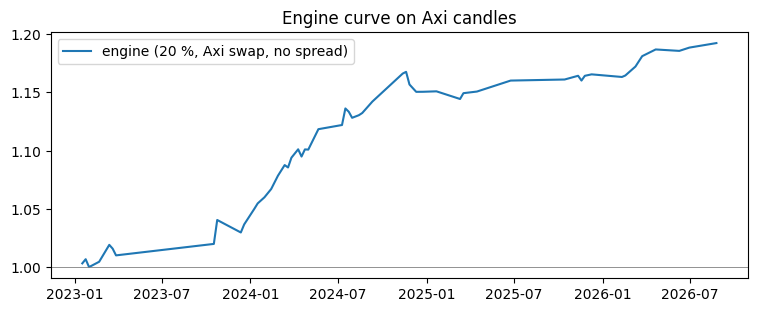

written: results/engine_trades.csv and results/engine_mondays.csv


In [5]:
trades_sized.to_csv(OUT_DIR / "engine_trades.csv", index=False)
mon.to_csv(OUT_DIR / "engine_mondays.csv", index=False)

eq = (1 + sz.size_fraction * trades.pnl / 100.0).cumprod()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(trades.exit_time, eq.values, label="engine (20 %, Axi swap, no spread)")
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Engine curve on Axi candles"); ax.legend(); plt.show()
print("written:", OUT_DIR / "engine_trades.csv", "and", OUT_DIR / "engine_mondays.csv")

---
## ► NOW GO TO METATRADER 5
Run the EA in the **Strategy Tester** with `BTC-JPY`, `H1`, from `2023-01-02` to `2026-10-23`, `InpEnableReporter=false` and `InpMaxSpreadBps=1000`:

- **Pass A** · *Open prices only* → save the report and the log as `tester/report_A.xlsx` and `tester/log_A.txt`
- **Pass B** · *1 minute OHLC* (or *real ticks*) → `tester/report_B.xlsx` and `tester/log_B.txt`

Then come back and run from section 5.

## 5 · TESTER READERS (REPORT AND LOG)

In [6]:
def server_to_utc(ts):
    # same rule as the EA: server is UTC+3 in US summer time, UTC+2 otherwise
    ts = pd.Series(pd.to_datetime(ts)).reset_index(drop=True)
    def nth_sunday(y, m, n):
        d0 = pd.Timestamp(y, m, 1)
        return d0 + pd.Timedelta(days=(6 - d0.weekday()) % 7 + 7 * (n - 1))
    approx = ts - pd.Timedelta(hours=2)
    summer = pd.Series(False, index=ts.index)
    for y in sorted(set(approx.dropna().dt.year)):
        ini = nth_sunday(y, 3, 2) + pd.Timedelta(hours=7)
        fin = nth_sunday(y, 11, 1) + pd.Timedelta(hours=6)
        summer |= (approx >= ini) & (approx < fin)
    return ts - pd.to_timedelta(summer.map({True: 3, False: 2}), unit="h")


def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[\s\u00a0\u202f]", "", regex=True).str.replace(",", ""), errors="coerce")


def _extract_deals(raw):
    raw = raw.reset_index(drop=True)
    hdr = None
    for i in range(len(raw)):
        vals = [str(v).strip() for v in raw.iloc[i].values]
        if "Direction" in vals and "Volume" in vals:
            hdr = i
            break
    if hdr is None:
        return None
    body = raw.iloc[hdr + 1:].copy()
    body.columns = [str(v).strip() for v in raw.iloc[hdr].values]
    body = body.loc[:, [c for c in body.columns if c not in ("nan", "")]]
    body = body.loc[:, ~body.columns.duplicated()]
    body["Time"] = pd.to_datetime(body["Time"], format="%Y.%m.%d %H:%M:%S", errors="coerce")
    body = body[body["Time"].notna()]
    for c in ("Volume", "Price", "Commission", "Swap", "Profit", "Balance"):
        if c in body.columns:
            body[c] = _num(body[c])
    return body.reset_index(drop=True)


def load_tester_deals(path):
    p = Path(path)
    if p.suffix.lower() in (".xlsx", ".xls"):
        return _extract_deals(pd.read_excel(p, header=None))
    if p.suffix.lower() in (".htm", ".html"):
        for enc in ("utf-16", "utf-8"):
            try:
                tabs = pd.read_html(p, encoding=enc, header=None)
            except Exception:
                continue
            for t in tabs:
                out = _extract_deals(t)
                if out is not None and len(out):
                    return out
        return None
    return _extract_deals(pd.read_csv(p, header=None, sep=None, engine="python"))


def tester_trades(deals):
    d = deals[deals["Direction"].astype(str).str.lower().isin(["in", "out"])]
    ins = d[d["Direction"].str.lower() == "in"].reset_index(drop=True)
    outs = d[d["Direction"].str.lower() == "out"].reset_index(drop=True)
    n = min(len(ins), len(outs))
    ins, outs = ins.iloc[:n], outs.iloc[:n]
    t = pd.DataFrame({
        "entry_srv": ins["Time"].values, "exit_srv": outs["Time"].values,
        "entry_price": ins["Price"].values, "exit_price": outs["Price"].values,
        "lots": ins["Volume"].values,
        "swap": outs["Swap"].values,
        "commission": ins["Commission"].values + outs["Commission"].values,
        "profit": outs["Profit"].values,
    })
    t["entry_utc"] = server_to_utc(t.entry_srv)
    t["exit_utc"] = server_to_utc(t.exit_srv)
    return t


RX_T     = re.compile(r"(\d{4}\.\d{2}\.\d{2} \d{2}:\d{2}:\d{2})")
RX_ENTRY = re.compile(r"ATR%=([0-9.]+)\s*\|\s*P=([0-9.]+)")
RX_SKIP  = re.compile(r"ATR%\s+([0-9.]+)\s*=\s*percentile\s+([0-9.]+)")


def parse_ea_log(path):
    raw = Path(path).read_bytes()
    txt = ""
    for enc in ("utf-16", "utf-8"):
        try:
            txt = raw.decode(enc)
        except Exception:
            continue
        if "ATR" in txt:
            break
    rows = []
    for line in txt.splitlines():
        m, kind = RX_ENTRY.search(line), "entry"
        if not m:
            m, kind = RX_SKIP.search(line), "skip"
        t = RX_T.search(line)
        if m and t:
            rows.append(dict(srv=pd.to_datetime(t.group(1), format="%Y.%m.%d %H:%M:%S"), kind=kind,
                             atr_log=float(m.group(1)), rank_log=float(m.group(2))))
    out = pd.DataFrame(rows, columns=["srv", "kind", "atr_log", "rank_log"])
    if len(out):
        out["key"] = server_to_utc(out.srv).dt.floor("h")
    return out

## 6 · TRADE-BY-TRADE COMPARISON

In [7]:
def reconcile(name, report_path, log_path):
    deals = load_tester_deals(report_path)
    if deals is None or deals.empty:
        raise ValueError(f"Could not read the trades from {report_path}. Send the first rows of the report and the reader gets adjusted.")
    tt = tester_trades(deals)

    e = trades.assign(key=trades.entry_time.dt.floor("h"), lots_e=sz.lots.values)
    t = tt.assign(key=tt.entry_utc.dt.floor("h"))
    both = e.merge(t, on="key", suffixes=("_e", "_t"))
    only_e = sorted(set(e.key) - set(t.key))
    only_t = sorted(set(t.key) - set(e.key))

    both["entry_bps"]   = (both.entry_price_t / both.entry_price_e - 1) * 1e4     # entry spread + slippage
    both["exit_bps"]    = (both.exit_price_t / both.exit_price_e - 1) * 1e4       # exit slippage (opposite sign)
    both["rt_cost_bps"] = both.entry_bps - both.exit_bps                          # round-trip cost
    both["exit_ok"]     = both.exit_utc.dt.floor("h") == both.exit_time.dt.floor("h")
    both["ret_e"]       = (both.exit_price_e / both.entry_price_e - 1) * 100
    both["ret_t"]       = (both.exit_price_t / both.entry_price_t - 1) * 100

    res = dict(
        run=name, n_engine=len(e), n_tester=len(t), n_entry_match=len(both),
        n_entry_and_exit_match=int(both.exit_ok.sum()),
        only_engine=[str(k) for k in only_e], only_tester=[str(k) for k in only_t],
        spread_per_side_bps_median=float(both.rt_cost_bps.median() / 2) if len(both) else None,
        spread_per_side_bps_mean=float(both.rt_cost_bps.mean() / 2) if len(both) else None,
        entry_bps_median=float(both.entry_bps.median()) if len(both) else None,
        exit_bps_median=float(both.exit_bps.median()) if len(both) else None,
        return_diff_pp_mean=float((both.ret_t - both.ret_e).mean()) if len(both) else None,
        lots_equal=float((both.lots_t.round(2) == both.lots_e.round(2)).mean()) if len(both) else None,
        lots_rel_diff_median=float((both.lots_t / both.lots_e - 1).median()) if len(both) else None,
        tester_swap_total=float(t.swap.sum()), tester_commission_total=float(t.commission.sum()),
        tester_net_profit=float((t.profit + t.swap + t.commission).sum()),
    )

    # --- Monday level: engine decision vs tester decision + percentile/ATR from the log
    mm = mon[~mon.first_monday].copy()
    mm["key"] = mm.entry_utc.dt.floor("h")
    mm["eng_trade"] = mm.traded
    mm["tst_trade"] = mm.key.isin(set(t.key))
    mm["cat"] = np.where(mm.eng_trade == mm.tst_trade, "ok",
                 np.where(~mm.full_window, "WARM-UP (window < 8760)",
                 np.where(mm.near_edge | mm.gap_near_atr, "EXPECTED EDGE", "LOGIC")))
    if log_path and Path(log_path).exists():
        lg = parse_ea_log(log_path)
        if len(lg):
            j = mm.merge(lg, on="key", how="inner")
            j["d_rank"] = j.rank_log - j.rank_pct
            j["d_atr_rel"] = j.atr_log / j.atr_pct - 1
            res.update(mondays_with_log=len(j),
                       d_rank_abs_max=float(j.d_rank.abs().max()), d_rank_abs_median=float(j.d_rank.abs().median()),
                       d_atr_rel_abs_max=float(j.d_atr_rel.abs().max()),
                       mondays_rank_diff_gt_1pt=int((j.d_rank.abs() > 1.0).sum()))
            mm = mm.merge(j[["key", "d_rank", "d_atr_rel"]], on="key", how="left")
    res["classification"] = {k: int(v) for k, v in mm.cat.value_counts().items()}
    return res, both, mm, t


results, frames = {}, {}
for label, cfg in (("A", TESTER_A), ("B", TESTER_B)):
    if Path(cfg["report"]).exists():
        results[label], b, m, t = reconcile(label, cfg["report"], cfg["log"])
        frames[label] = dict(both=b, mondays=m, tester=t)
        r = results[label]
        print(f"Pass {label}: {r['n_entry_and_exit_match']} of {r['n_engine']} engine trades match "
              f"({r['n_tester']} in the tester) | engine only {len(r['only_engine'])} | tester only {len(r['only_tester'])}")
        print(f"   spread per side (median): {r['spread_per_side_bps_median']:.1f} bps | classification: {r['classification']}")
    else:
        print(f"Pass {label}: pending ({cfg['report']} does not exist yet)")

Pass A: pending (tester/report_A.xlsx does not exist yet)
Pass B: pending (tester/report_B.xlsx does not exist yet)


## 7 · MONDAYS WHERE ENGINE AND TESTER DISAGREE

In [8]:
for label, f in frames.items():
    bad = f["mondays"][f["mondays"].cat != "ok"]
    print(f"--- Pass {label}: {len(bad)} Mondays with a discrepancy")
    if len(bad):
        display(bad[["entry_utc", "atr_pct", "rank_pct", "eng_trade", "tst_trade", "near_edge", "gap_near_atr", "full_window", "cat"]])
if not frames:
    print("Pending: no tester results yet.")

Pending: no tester results yet.


## 8 · CURVE: ENGINE VS TESTER

In [9]:
if frames:
    label = "B" if "B" in frames else "A"
    t = frames[label]["tester"]
    eq_t = (DEPOSIT + (t.profit + t.swap + t.commission).cumsum()) / DEPOSIT
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.plot(trades.exit_time, (1 + sz.size_fraction * trades.pnl / 100.0).cumprod().values, label="engine (no spread)")
    ax.plot(t.exit_utc, eq_t.values, label=f"tester pass {label} (with spread)")
    ax.axhline(1, color="grey", lw=0.6)
    ax.set_title("Engine vs Strategy Tester (equity at each trade close)"); ax.legend(); plt.show()

    # engine with the measured spread: it should get close to the tester
    cost = results[label]["spread_per_side_bps_median"]
    tr_c = me.run_monday_backtest(df, cost_bps_per_side=cost, **PARAMS)
    tr_c = tr_c[(tr_c.entry_time >= TESTER_START) & (tr_c.entry_time <= TESTER_END)]
    sz_c = me.cfd_trade_sizes(tr_c.reset_index(drop=True), DEPOSIT, compounding=True)
    ret_c = float((1 + sz_c.size_fraction.values * tr_c.pnl.values / 100.0).prod() - 1)
    ret_t = float(eq_t.iloc[-1] - 1)
    print(f"total return: engine with measured spread ({cost:.1f} bps/side) {ret_c:+.1%} | tester {ret_t:+.1%}")
    results[label]["engine_return_with_measured_spread"] = ret_c
    results[label]["tester_return"] = ret_t
else:
    print("Pending: no tester results yet.")

Pending: no tester results yet.


## 9 · SAVE `reconciliacion_mt5_axi.json`

In [10]:
if results:
    out = dict(
        strategy="MONDAY.btcusd.cfd.v1", symbol="BTC-JPY (Axi)", range=[TESTER_START, TESTER_END],
        params=dict(**PARAMS, **ENGINE), deposit=DEPOSIT, runs=results,
        criterion="X of N trades match; discrepancies classified as LOGIC (must be 0), EXPECTED EDGE, WARM-UP or execution",
    )
    path = OUT_DIR / "reconciliacion_mt5_axi.json"
    path.write_text(json.dumps(out, indent=2, default=str, ensure_ascii=False))
    print("written:", path)
else:
    print("Pending: no tester results yet.")

Pending: no tester results yet.
